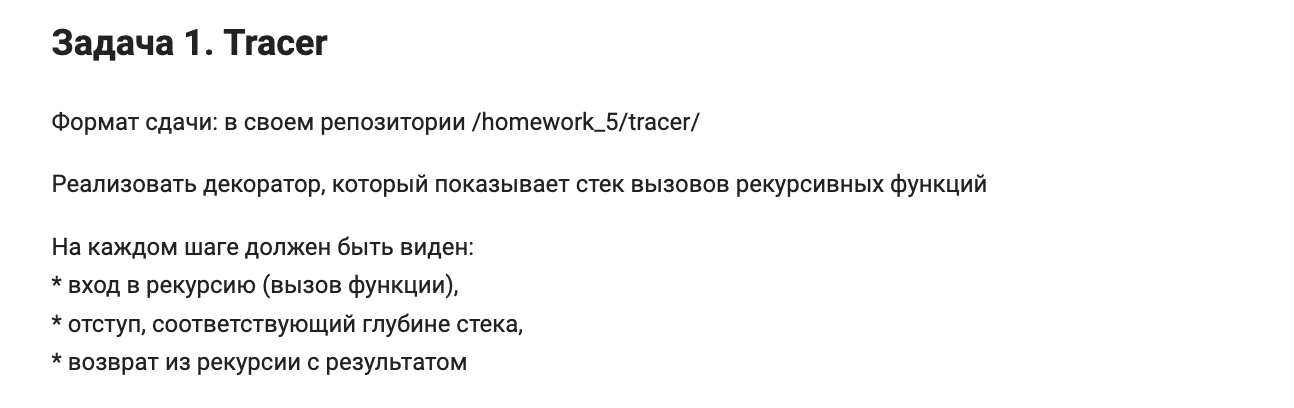

# Ход решения

Сделаем декоратор `tracer`, который принимает функцию и возвращает её обёртку `wrapper`. При вызове обёртка сначала печатает имя функции и её аргументы, затем вызывает исходную функцию, а после её завершения печатает результат.

Для отступов будем хранить `depth` — количество активных вызовов обёртки. При входе увеличиваем его на `1`, при возврате уменьшаем на `1`. Выражение `"  " * depth` даёт нужный отступ, потому что мы просто число пробелов умножаем на глубину, чтобы показывать как бы насколько глубоко ушла наша рекурсия. `nonlocal` нужен, чтобы изменять переменную `depth` из внешней функции `tracer`.

Рекурсия тоже отслеживается: после `@tracer` имя декорированной функции указывает на `wrapper`, поэтому каждый вложенный вызов снова проходит через него.

В блоке `try` вызываем исходную функцию и получаем её результат. Блок `finally` выполняется в любом случае, даже если внутри функции возникла ошибка. Поэтому именно в нём уменьшаем `depth`, чтобы глубина всегда корректно восстанавливалась. При этом `finally` не перехватывает саму ошибку.

В конце печатаем и возвращаем исходный результат без изменений.

# Граничные случаи

- Вызов без рекурсии печатается с нулевым отступом.
- Поддерживаются позиционные и именованные аргументы, а также функции без аргументов.
- Повторный вызов начинается с глубины `0`.
- Если функция выбрасывает исключение, счётчик глубины всё равно восстанавливается, а само исключение передаётся дальше.

# Сложность алгоритма

Пусть `k` — число вызовов функции, `h` — максимальная глубина, `S` — суммарная длина выводимых аргументов и результатов.

- **Время:** `O(kh + S)` на формирование и печать логов: на одном уровне отступ может содержать до `O(h)` пробелов. Само изменение счётчика занимает `O(1)` на вызов. Время работы исходной функции учитывается отдельно.
- **Память:** `O(1)` на счётчик глубины, `O(h)` на стек вызовов обёртки; временные строки дополнительно занимают память, пропорциональную длине выводимой строки. Все логи в списке не храним.

# Реализация алгоритма

In [9]:
from functools import wraps


def tracer(func):
    depth = 0

    @wraps(func)
    def wrapper(*args, **kwargs):
        nonlocal depth

        indent = "  " * depth
        print(f"{indent}{func.__name__}{args}")

        depth += 1
        try:
            result = func(*args, **kwargs)
        finally:
            depth -= 1

        print(f"{indent}{func.__name__} = {result}")
        return result

    return wrapper

# Проверка на нетривиальном примере

In [10]:
@tracer
def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n - 1)


factorial(4)

factorial(4,)
  factorial(3,)
    factorial(2,)
      factorial(1,)
      factorial = 1
    factorial = 2
  factorial = 6
factorial = 24


24

# Визуализация работы алгоритма

Для `factorial(4)` сначала последовательно вызываются `factorial(4)`, `factorial(3)`, `factorial(2)` и `factorial(1)`. Последний вызов возвращает `1`, после чего на обратном пути вычисляются `2`, `6` и `24`.

| Шаг | Что происходит | Глубина | Результат |
| ---: | --- | ---: | --- |
| 1 | Вход в `factorial(4)` | 0 | Пока неизвестен |
| 2 | Вход в `factorial(3)` | 1 | Пока неизвестен |
| 3 | Вход в `factorial(2)` | 2 | Пока неизвестен |
| 4 | Вход в `factorial(1)` | 3 | Базовый случай |
| 5 | Возврат из `factorial(1)` | 3 | `1` |
| 6 | Возврат из `factorial(2)` | 2 | `2 * 1 = 2` |
| 7 | Возврат из `factorial(3)` | 1 | `3 * 2 = 6` |
| 8 | Возврат из `factorial(4)` | 0 | `4 * 6 = 24` |

Вывод декоратора:

```text
 factorial(4)
   factorial(3)
     factorial(2)
       factorial(1)
       factorial = 1
     factorial = 2
   factorial = 6
 factorial = 24
```

Таким образом, отступ растёт на прямом пути рекурсии и уменьшается при возвращении к предыдущим вызовам.

# Тесты

Проверим обычную рекурсию, базовый случай, ветвление Фибоначчи, именованные аргументы, повторные вызовы и восстановление глубины после ошибки. Используем `StringIO`, чтобы сравнивать именно напечатанные строки.

In [13]:
import unittest
from contextlib import redirect_stdout
from io import StringIO


class TestTracer(unittest.TestCase):
    def capture(self, func, *args, **kwargs):
        output = StringIO()
        with redirect_stdout(output):
            result = func(*args, **kwargs)
        return result, output.getvalue().splitlines()

    def test_factorial(self):
        result, lines = self.capture(factorial, 3)
        self.assertEqual(result, 6)
        self.assertEqual(lines, [
            'factorial(3,)',
            '  factorial(2,)',
            '    factorial(1,)',
            '    factorial = 1',
            '  factorial = 2',
            'factorial = 6',
        ])

    def test_base_case(self):
        self.assertEqual(
            self.capture(factorial, 1),
            (1, ['factorial(1,)', 'factorial = 1'])
        )

    def test_fibonacci(self):
        @tracer
        def fib(n):
            if n <= 1:
                return n
            return fib(n - 1) + fib(n - 2)

        result, lines = self.capture(fib, 3)
        self.assertEqual(result, 2)
        self.assertEqual(len(lines), 10)
        self.assertEqual(lines[0], 'fib(3,)')
        self.assertEqual(lines[-1], 'fib = 2')

    def test_kwargs_and_no_args(self):
        @tracer
        def add(a, b=0):
            return a + b

        @tracer
        def answer():
            return 42

        self.assertEqual(
            self.capture(add, 2, b=3),
            (5, ['add(2,)', 'add = 5'])
        )
        self.assertEqual(
            self.capture(answer),
            (42, ['answer()', 'answer = 42'])
        )
        self.assertEqual(add.__name__, 'add')

    def test_repeat_call(self):
        self.capture(factorial, 4)
        result, lines = self.capture(factorial, 2)
        self.assertEqual(result, 2)
        self.assertEqual(lines[0], 'factorial(2,)')

    def test_exception(self):
        @tracer
        def sometimes_fails(n):
            if n < 0:
                raise ValueError('wrong number')
            return n

        with redirect_stdout(StringIO()):
            with self.assertRaises(ValueError):
                sometimes_fails(-1)

        result, lines = self.capture(sometimes_fails, 0)
        self.assertEqual(result, 0)
        self.assertEqual(lines[0], 'sometimes_fails(0,)')


_ = unittest.main(argv=[''], exit=False)

......
----------------------------------------------------------------------
Ran 6 tests in 0.010s

OK
